In [18]:
# env: spaceapps
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import joblib
import cv2
from sklearn.metrics.pairwise import cosine_similarity

from pandas.core.common import flatten

import torch 
import torch.nn as nn

import torchvision.models as models
import torchvision.transforms as transforms
from torch.autograd import Variable

from PIL import Image
import warnings
warnings.filterwarnings("ignore")
import os

In [2]:
def image_location(img):
    return "data/" + img

# function to load image
def import_img(image):
    img_path = image_location(image)
    if not os.path.exists(img_path):
        return None  # Or handle as needed
    img = cv2.imread(img_path)
    if img is None:
        return None
    return img

In [3]:
def show_images(images,rows=1,cols=1,figsize=(12,12)):
    
    # define fig 
    fig,axes = plt.subplots(ncols=cols,nrows=rows,figsize=figsize)
    
    for index,name in enumerate(images):
        axes.ravel()[index].imshow(cv2.cvtColor(images[name], cv2.COLOR_BGR2RGB))
        axes.ravel()[index].set_title(name)
        axes.ravel()[index].set_axis_off()
    plt.tight_layout()

In [5]:
width = 224
height = 224

resnetmodel = models.resnet18(pretrained=True)
resnetmodel.eval()
layer = resnetmodel._modules.get("avgpool")

1.1%

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/luis-carlos/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%


In [7]:
from torchinfo import summary

summary(resnetmodel, input_size=(1,3,224,224),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
ResNet (ResNet)                          [1, 3, 224, 224]     [1, 1000]            --                   True
├─Conv2d (conv1)                         [1, 3, 224, 224]     [1, 64, 112, 112]    9,408                True
├─BatchNorm2d (bn1)                      [1, 64, 112, 112]    [1, 64, 112, 112]    128                  True
├─ReLU (relu)                            [1, 64, 112, 112]    [1, 64, 112, 112]    --                   --
├─MaxPool2d (maxpool)                    [1, 64, 112, 112]    [1, 64, 56, 56]      --                   --
├─Sequential (layer1)                    [1, 64, 56, 56]      [1, 64, 56, 56]      --                   True
│    └─BasicBlock (0)                    [1, 64, 56, 56]      [1, 64, 56, 56]      --                   True
│    │    └─Conv2d (conv1)               [1, 64, 56, 56]      [1, 64, 56, 56]      36,864               True
│    │    └─BatchN

In [8]:
# Transform pipline
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225])
])
missing_img = []

In [9]:
def vector_extraction(resnetmodel, image_path):
    try:
        # Load Image
        img = Image.open(image_path).convert("RGB")
        img_tensor = transform(img).unsqueeze(0)
        embeddings = torch.zeros(512)

        # Hook function
        def copy_data(module, input, output):
            embeddings.copy_(output.data.reshape(output.data.size(1)))
        hook = layer.register_forward_hook(copy_data)

        with torch.no_grad():
            resnetmodel(img_tensor)
        hook.remove()

        return embeddings.clone()
    except Exception as e:
        print(f"Error processing image {image_path}: {e}")
        missing_img.append(image_path)
        return None

In [12]:
img_path = 'aerial_image.png'

In [13]:
sample_embedding_0 = vector_extraction(resnetmodel, image_location(img_path))

In [ ]:
print(sample_embedding_0)

tensor([7.3083e-01, 1.7280e-01, 1.1104e+00, 8.3956e-02, 0.0000e+00, 4.5945e-01,
        4.4470e-01, 1.9198e+00, 4.6871e+00, 3.6249e-01, 7.2657e-01, 5.9249e-02,
        1.3072e-02, 1.3199e+00, 1.0557e+00, 8.4114e-01, 2.0682e-01, 3.5621e-01,
        8.1705e-01, 8.6839e-01, 3.3475e-01, 9.0168e-02, 4.2070e-02, 1.3090e+00,
        1.5431e+00, 2.0318e-01, 4.4102e-02, 4.5473e-01, 9.8866e-01, 2.8379e-01,
        2.2795e-01, 3.8776e-01, 5.6057e-02, 7.7138e-02, 5.1038e-01, 5.3279e-01,
        0.0000e+00, 6.3861e-01, 4.3321e-01, 1.3017e-02, 4.8889e-02, 6.4672e-02,
        4.6809e-01, 5.9782e-01, 1.2958e-01, 1.2726e+00, 4.2139e-01, 3.4847e-03,
        1.7053e+00, 4.4335e-01, 1.1350e+00, 1.1803e+00, 1.7515e-01, 5.2769e-01,
        1.9297e+00, 4.7469e-01, 1.0124e+00, 3.5053e-01, 2.7017e+00, 4.9671e-02,
        1.9586e-01, 5.2436e-01, 1.0683e+00, 9.7034e-01, 8.3206e-01, 2.4445e-01,
        2.1102e+00, 7.0425e-02, 2.6706e-01, 9.9519e-03, 2.6483e-01, 2.7464e-01,
        4.0076e-01, 3.1925e-01, 7.5108e-

In [19]:
img = import_img(img_path)

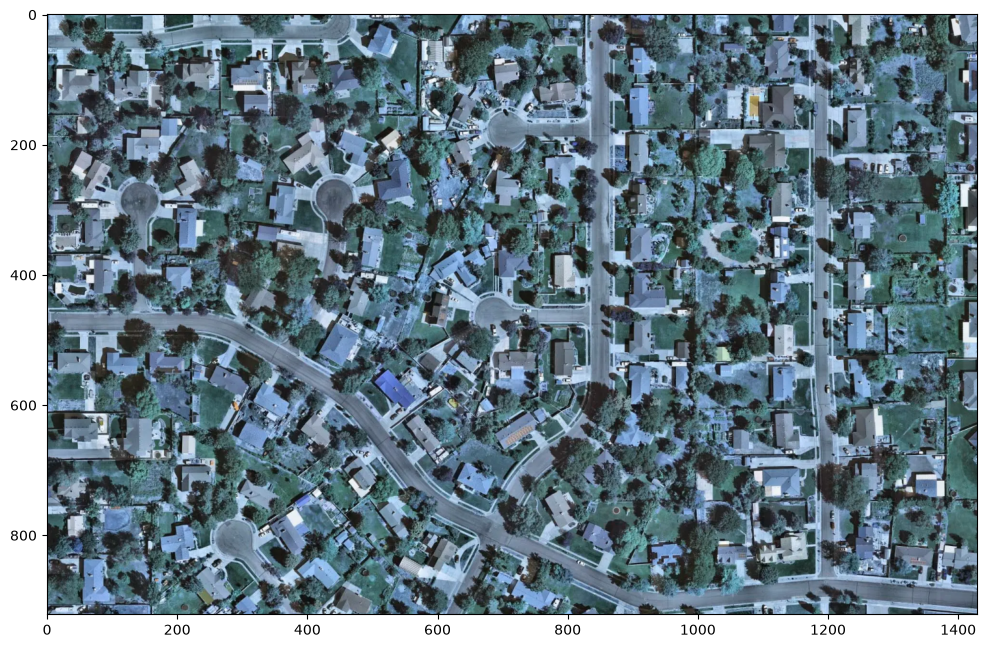

In [24]:
plt.figure(figsize=(12, 12))
plt.imshow(img)
plt.show()

In [39]:
x = img.shape[0]
y = img.shape[1]

print(x, y)

922 1429


## Extracting an embedding for a pixel

In [26]:
img.shape

(922, 1429, 3)

In [29]:
type(img)

numpy.ndarray

In [ ]:
#import torch
#import torchvision.models as models
#import torchvision.transforms as transforms
#from PIL import Image


In [30]:
# 1. Load a pre-trained model (e.g., ResNet50) up to a convolutional layer
# We remove the final pooling and fully connected layers to keep spatial maps
resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
feature_extractor = torch.nn.Sequential(*(list(resnet.children())[:-2]))
feature_extractor.eval()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/luis-carlos/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100.0%


Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, ker

In [31]:
# 2. Prepare an image
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [33]:
image = Image.open('./data/' + img_path).convert("RGB")
input_tensor = transform(image).unsqueeze(0)  # Shape: (1, 3, 224, 224)
input_tensor

tensor([[[[ 1.4440,  1.9578,  1.6667,  ...,  0.6392,  1.1358,  1.1529],
          [ 1.4954,  1.8893,  1.7180,  ...,  0.6049,  1.1358,  0.6734],
          [ 1.3927,  2.0092,  1.9064,  ...,  0.5536,  1.1015,  0.7248],
          ...,
          [-1.0048, -1.1418, -0.0801,  ...,  0.4166,  0.0227, -0.1486],
          [-0.8849,  0.0569,  1.7009,  ...,  1.2385,  1.2557,  1.2385],
          [ 0.1083,  0.9474,  1.4098,  ..., -0.0116,  0.1768,  0.5364]],

         [[ 1.0805,  1.6408,  1.3256,  ...,  0.3102,  0.7829,  0.7654],
          [ 1.0980,  1.5532,  1.4132,  ...,  0.2752,  0.7829,  0.3277],
          [ 1.0105,  1.6933,  1.6057,  ...,  0.2402,  0.7654,  0.4678],
          ...,
          [-1.1253, -1.1253, -0.0749,  ...,  0.1702, -0.1275, -0.2850],
          [-0.9153, -0.1099,  1.5007,  ...,  0.9580,  0.9580,  0.8880],
          [-0.0049,  0.6429,  1.0805,  ..., -0.2150, -0.0224,  0.2052]],

         [[ 0.7402,  1.3851,  1.0714,  ...,  0.1476,  0.6008,  0.5834],
          [ 0.7751,  1.2980,  

In [34]:
# 3. Forward pass to get feature maps
with torch.no_grad():
    feature_maps = feature_extractor(input_tensor) 
    # Shape will be (1, 2048, H_out, W_out), e.g., (1, 2048, 7, 7)

In [40]:
# 1. Get the spatial dimensions of your extracted feature map (H_feat, W_feat)
_, channels, feature_h, feature_w = feature_maps.shape

In [41]:
# Original image dimensions (Height, Width)
orig_h, orig_w = y, x  

# Target pixel in original image coordinates
target_y, target_x = 800, 200

In [42]:
# 2. Scale coordinates down to feature map dimensions
feat_y = int((target_y / orig_h) * feature_h)
feat_x = int((target_x / orig_w) * feature_w)

# Clamp values to avoid edge boundary overflow
feat_y = min(feat_y, feature_h - 1)
feat_x = min(feat_x, feature_w - 1)

# 3. Extract the embedding vector
pixel_embedding = feature_maps[0, :, feat_y, feat_x]

In [43]:
print(f"Mapped image pixel ({target_y}, {target_x}) -> feature map cell ({feat_y}, {feat_x})")
print("Embedding shape:", pixel_embedding.shape)

Mapped image pixel (800, 200) -> feature map cell (3, 1)
Embedding shape: torch.Size([2048])


In [45]:
print(pixel_embedding) # pixel_embedding

tensor([0., 0., 0.,  ..., 0., 0., 0.])


In [47]:
print(pixel_embedding.detach().numpy()) #pixel_embedding.detach().numpy()

[0. 0. 0. ... 0. 0. 0.]


In [49]:
pixel_embedding.tolist()

[0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.6507824063301086,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.6606296300888062,
 0.0,
 0.0,
 0.0,
 0.16772551834583282,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.04474318027496338,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.3242744207382202,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.22490307688713074,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 1.339336633682251,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.8088720440864563,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.7965452671051025,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,